<a href="https://colab.research.google.com/github/TianaT6/MSSP607/blob/main/Modules/Week_7/MSSP6070_Week7_Participation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 1. Load the data

Only the order date and sales amount are needed for this chart.


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter
from pathlib import Path

file_path = Path("InternetSales.csv")
if not file_path.exists():
    from google.colab import files
    files.upload()

sales = pd.read_csv(file_path, usecols=["OrderDate", "SalesAmount"], encoding="latin1")
sales["OrderDate"] = pd.to_datetime(sales["OrderDate"], format="%m/%d/%Y")
sales.head()


Saving InternetSales.csv to InternetSales.csv


,SalesAmount,OrderDate
0,3399.99,2011-01-19
1,2319.99,2013-01-18
2,21.98,2013-01-18
3,2384.07,2013-05-03
4,28.99,2013-05-03


## 2. Calculate yearly sales

Group by the year of OrderDate and add SalesAmount within each year.


In [2]:
sales["Year"] = sales["OrderDate"].dt.year
yearly_sales = sales.groupby("Year")["SalesAmount"].sum()
yearly_sales


,SalesAmount
Year,
2010,4.342104e+04
2011,7.075526e+06
2012,5.842485e+06
2013,1.635155e+07
2014,4.569472e+04


## 3. Create the bar chart and save it as a PDF


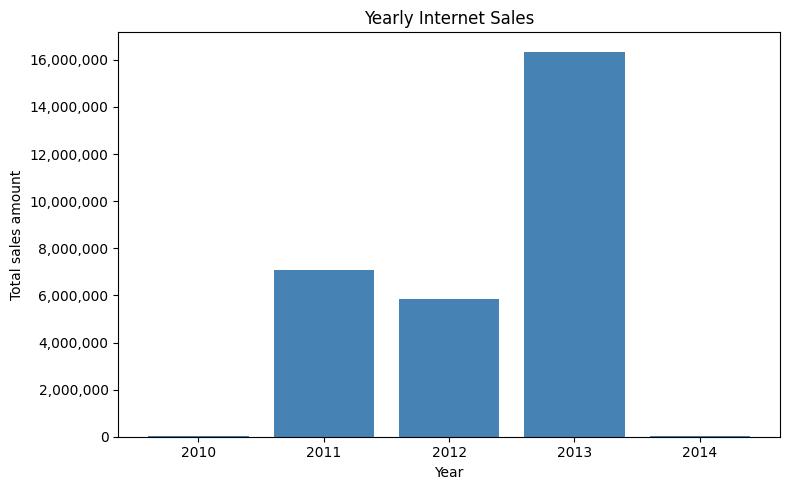

Saved: Yearly_Internet_Sales.pdf


In [3]:
plt.figure(figsize=(8, 5))
plt.bar(yearly_sales.index.astype(str), yearly_sales.values, color="steelblue")
plt.title("Yearly Internet Sales")
plt.xlabel("Year")
plt.ylabel("Total sales amount")
plt.gca().yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
plt.tight_layout()
plt.savefig("Yearly_Internet_Sales.pdf", format="pdf", bbox_inches="tight")
plt.show()
print("Saved: Yearly_Internet_Sales.pdf")
